# 커널 SVM 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/ml1/week02/3_svm_kernel/lab/svm_kernel.ipynb)

겹치는 데이터는 소프트 마진으로, 직선으로 못 가르는 데이터는 특징 늘리기와 커널로 가른다.

- **파트 0**: 슬라이드의 점에 이상치 하나 넣고 소프트 마진
- **파트 1**: 원 데이터: 특징 6개를 직접 만들기 (A) vs 다항 커널 (B) 가 같은 w 인지 확인
- **파트 2**: 지폐 1,372장 진위 판별: 선형 vs RBF
- **파트 3**: 반달 데이터에서 C 와 γ 를 교차 검증으로

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_circles, make_moons

## 슬라이드의 예시 데이터

원래 값에서 축마다 평균을 빼고 표준편차로 나눈다 (z-score). 슬라이드의 점은 이 값을 소수 첫째 자리로 반올림한 것.

In [ ]:
# Same example as the slides: 10 red (+1) and 10 blue (-1) points, raw values
X_raw = np.array([[5.9, 6.8], [5.3, 8.0], [6.3, 6.2], [6.1, 9.2], [5.5, 7.4], [6.6, 8.6], [5.7, 5.6], [5.5, 9.8], [6.6, 6.8], [4.8, 8.9],   # red
              [4.4, 1.1], [3.8, 1.7], [4.6, 2.3], [4.0, 3.2], [3.6, 0.5], [4.4, 3.8], [5.1, 1.7], [3.4, 3.2], [4.8, 0.8], [3.7, 4.4]])  # blue
y = np.array([1] * 10 + [-1] * 10)
X = None  # TODO: z-score each column, round to 1 decimal
print("mean", X.mean(0).round(2), " std", X.std(0).round(2))

def plot_svm(model, X, y, ax=None, title=""):
    ax = ax or plt.gca()
    gx, gy = np.meshgrid(np.linspace(-2.2, 2.2, 200), np.linspace(-2.2, 2.2, 200))
    Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm_r")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="gold", linewidths=2)
    ax.set_aspect("equal"); ax.set_title(title)

**예상 결과**

```
mean [0.01 0.  ]  std [0.99 1.01]
```

## 파트 0. 소프트 마진

빨간 이상치 하나를 파란 쪽에 넣는다. sklearn 의 `C` 는 슬라이드의 $C$ 와 같다: 크면 좁은 길, 작으면 넓은 길. 마진 $M = 1/\lVert\mathbf{w}\rVert$.

In [ ]:
# Soft margin: add one red outlier inside the blue group
X_out = np.r_[X, [[-0.2, -0.6]]]; y_out = np.r_[y, [1]]
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, C in zip(axs, [100, 3, 0.3]):
    m = SVC(kernel="linear", C=C).fit(X_out, y_out)
    n_sv = None  # TODO: number of support vectors
    plot_svm(m, X_out, y_out, ax, f"C={C}: M {1 / np.linalg.norm(m.coef_[0]):.2f}, {n_sv} SVs")   # margin M = 1/||w|| (nearest value = 1)
plt.show()

**예상 결과**

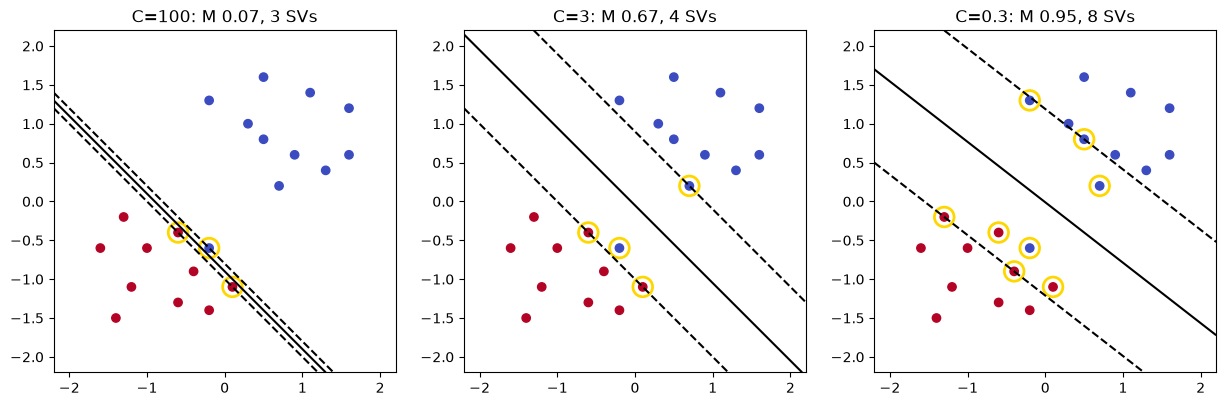

## 파트 1. 특징 직접 만들기 (A) vs 커널 (B)

다항 2차 커널 $(\mathbf{x}\cdot\mathbf{x}' + 1)^2$ 의 특징 6개: $\varphi(\mathbf{x}) = (1, \sqrt2x_1, \sqrt2x_2, x_1^2, \sqrt2x_1x_2, x_2^2)$.

- A: 점마다 $\varphi$ 6개를 만들고 선형 SVM 으로 $\mathbf{w}$ 6개 학습 (K 안 씀)
- B: 원래 점 그대로 다항 커널 SVM 으로 $\alpha$ (점마다 하나) 학습 → $\mathbf{w} = \sum_k \alpha_k y_k \varphi(\mathbf{x}_k)$ 로 계산 (sklearn `dual_coef_` = $\alpha_k y_k$)

In [ ]:
X, y = make_circles(120, factor=0.4, noise=0.06, random_state=1)
y = 2 * y - 1                                              # labels +1 / -1

def phi6(x):
    r2 = np.sqrt(2)
    return np.array([1, r2 * x[0], r2 * x[1], x[0] ** 2, r2 * x[0] * x[1], x[1] ** 2])

F = np.array([phi6(x) for x in X])                         # A: 6 features per point
model_a = SVC(kernel="linear", C=1).fit(F, y)
model_b = SVC(kernel="poly", degree=2, coef0=1, gamma=1, C=1).fit(X, y)   # B: kernel (x.x' + 1)^2

alpha_y = model_b.dual_coef_[0]                            # alpha_k * y_k of the support vectors (the others are 0)
w_b = None  # TODO: w = sum_k alpha_k * y_k * phi(x_k)
print("A  w =", model_a.coef_[0].round(3), " b =", model_a.intercept_.round(3))
print("B  w =", w_b.round(3), " b =", model_b.intercept_.round(3))
print("alpha: one per training point =", len(X), ", nonzero =", len(alpha_y))
print("same predictions:", (model_a.predict(F) == model_b.predict(X)).all())

**예상 결과**

```
A  w = [ 0.     0.108  0.126 -2.812  0.017 -3.095]  b = [1.643]
B  w = [-0.     0.108  0.126 -2.812  0.017 -3.095]  b = [1.643]
alpha: one per training point = 120 , nonzero = 21
same predictions: True
```

## 파트 2. 실제 데이터: 지폐 진위 판별

지폐 사진을 웨이블릿 변환해서 뽑은 특징 4개(분산, 왜도, 첨도, 엔트로피) 로 진짜(0) / 위조(1) 를 가린다. 처음 실행하면 내려받는다.

In [ ]:
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/banknote.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/banknote.csv")
df = pd.read_csv("data/banknote.csv", header=None, names=["variance", "skewness", "curtosis", "entropy", "fake"])
Xb, yb = df.iloc[:, :4].to_numpy(), df["fake"].to_numpy()
print(df.shape, "fake rate", round(yb.mean(), 3))
for kernel in ["linear", "rbf"]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    acc = None  # TODO: 5-fold CV accuracy
    print(f"{kernel:6s}: CV accuracy {acc:.4f}")

**예상 결과**

```
(1372, 5) fake rate 0.445
linear: CV accuracy 0.9861
rbf   : CV accuracy 1.0000
```

## 파트 3. C 와 γ 고르기

반달 데이터. `GridSearchCV` 는 모든 (C, γ) 조합을 교차 검증해서 가장 좋은 것을 고른다. sklearn 의 `C` 는 지난 시간 슬라이드의 $C$ 와 같다 (크면 좁은 길).

In [ ]:
Xm, ym = make_moons(300, noise=0.25, random_state=0)
grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.1, 1, 10, 100]}, cv=5)
grid.fit(Xm, ym)
print("best:", grid.best_params_, " CV accuracy", round(grid.best_score_, 3))
table = pd.DataFrame(grid.cv_results_["mean_test_score"].reshape(4, 4), index=[0.1, 1, 10, 100], columns=[0.1, 1, 10, 100])
print("rows = C, columns = gamma"); print(table.round(3))

**예상 결과**

```
best: {'C': 10, 'gamma': 1}  CV accuracy 0.963
rows = C, columns = gamma
       0.1    1.0    10.0   100.0
0.1    0.810  0.907  0.953  0.880
1.0    0.837  0.957  0.960  0.927
10.0   0.870  0.963  0.953  0.917
100.0  0.943  0.950  0.923  0.917
```

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
gx, gy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 250))
for ax, g in zip(axs, [0.1, grid.best_params_["gamma"], 100]):
    m = SVC(kernel="rbf", C=grid.best_params_["C"], gamma=g).fit(Xm, ym)
    Z = m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, Z > 0, alpha=0.2); ax.contour(gx, gy, Z, levels=[0], colors="k")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, s=10); ax.set_title(f"gamma={g}")
plt.show()

**예상 결과**

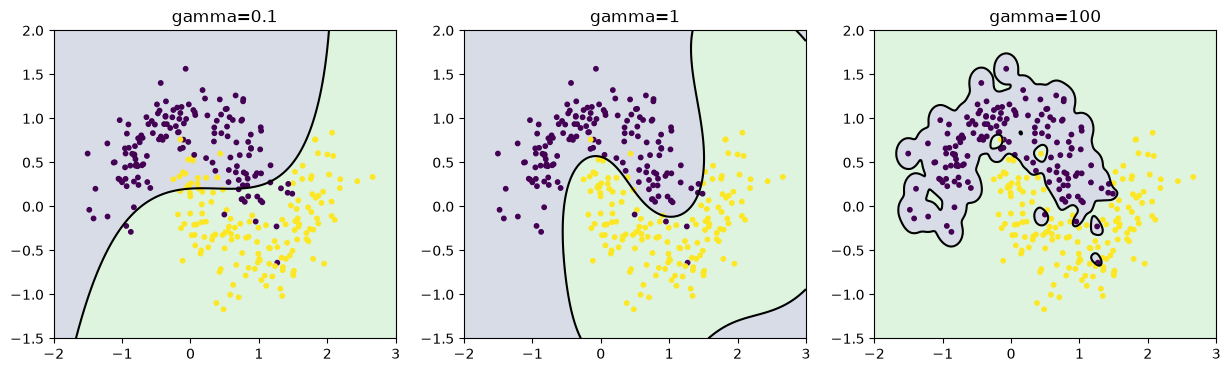

**확인 질문**
1. 파트 1 에서 α 는 몇 개이고, w 는 몇 개인가? 둘이 왜 다른가?
2. 파트 1 을 RBF 커널로 바꾸면 A 방법으로 같은 걸 할 수 있나? 왜?
3. 파트 2 에서 RBF 가 선형보다 조금 높다. 그래도 선형을 고를 이유가 있다면 무엇일까? (서포트 벡터 수, 예측 속도, 설명하기 쉬움)
4. 파트 3 의 표에서 C 와 γ 가 둘 다 클 때 정확도가 떨어지는 이유는?
5. 파트 0 에서 C 를 줄일수록 서포트 벡터 수는 어떻게 되나? 왜 그럴까?

데이터 출처: Banknote Authentication, UCI Machine Learning Repository (Volker Lohweg, 2012).